An end-to-end machine learning, exploratory data analysis, and risk intelligence system designed for financial institutions, payment processors, and e-commerce platforms to detect fraudulent transactions in real time, minimize financial loss, and reduce operational friction.

# 1.Environment Setup, Data Loading & Comprehensive Data Profiling

In this notebook cell, we initialize our environment, load the dataset, and execute the complete suite of required initial profile checks to inspect data health, anomalies, data types, missingness, and target distribution.

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

DATA_PATH = "/kaggle/input/datasets/bhadramohit/credit-card-fraud-detection/credit_card_fraud_dataset.csv" # Fallback to local name if needed
try:
    df = pd.read_csv(DATA_PATH)
except FileNotFoundError:

    print("Default path not found. Please verify the Kaggle dataset mount path.")

print(f"Dataset successfully loaded. Shape: {df.shape}")
display(df.head())


def perform_data_profiling(data):
    print("=" * 60)
    print("1. DATASET DIMENSIONS")
    print("=" * 60)
    print(f"Total Rows: {data.shape[0]:,}")
    print(f"Total Columns: {data.shape[1]}")
    
    print("\n" + "=" * 60)
    print("2. DATA TYPES & NON-NULL COUNTS")
    print("=" * 60)
    print(data.info())
    
    print("\n" + "=" * 60)
    print("3. MISSING VALUES PER COLUMN")
    print("=" * 60)
    missing = data.isnull().sum()
    missing_pct = (missing / len(data)) * 100
    missing_df = pd.DataFrame({'Missing Count': missing, 'Missing Percentage (%)': missing_pct})
    print(missing_df[missing_df['Missing Count'] > 0])
    if missing.sum() == 0:
        print("No missing values detected across any column.")
        
    print("\n" + "=" * 60)
    print("4. DUPLICATE RECORDS")
    print("=" * 60)
    duplicates = data.duplicated().sum()
    print(f"Number of duplicate rows: {duplicates:,}")
    
    print("\n" + "=" * 60)
    print("5. UNIQUE VALUES PER COLUMN")
    print("=" * 60)
    print(data.nunique())
    
    print("\n" + "=" * 60)
    print("6. STATISTICAL SUMMARY (NUMERIC FIELDS)")
    print("=" * 60)
    display(data.describe().T)
    
    print("\n" + "=" * 60)
    print("7. TARGET VARIABLE DISTRIBUTION (IsFraud)")
    print("=" * 60)
    fraud_counts = data['IsFraud'].value_counts()
    fraud_pct = data['IsFraud'].value_counts(normalize=True) * 100
    target_summary = pd.DataFrame({'Count': fraud_counts, 'Percentage (%)': fraud_pct})
    display(target_summary)

perform_data_profiling(df)

Dataset successfully loaded. Shape: (100000, 7)


,TransactionID,TransactionDate,Amount,MerchantID,TransactionType,Location,IsFraud
0,1,2024-04-03 14:15:35.462794,4189.27,688,refund,San Antonio,0
1,2,2024-03-19 13:20:35.462824,2659.71,109,refund,Dallas,0
2,3,2024-01-08 10:08:35.462834,784.00,394,purchase,New York,0
3,4,2024-04-13 23:50:35.462850,3514.40,944,purchase,Philadelphia,0
4,5,2024-07-12 18:51:35.462858,369.07,475,purchase,Phoenix,0


1. DATASET DIMENSIONS
Total Rows: 100,000
Total Columns: 7

2. DATA TYPES & NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 7 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   TransactionID    100000 non-null  int64  
 1   TransactionDate  100000 non-null  object 
 2   Amount           100000 non-null  float64
 3   MerchantID       100000 non-null  int64  
 4   TransactionType  100000 non-null  object 
 5   Location         100000 non-null  object 
 6   IsFraud          100000 non-null  int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 5.3+ MB
None

3. MISSING VALUES PER COLUMN
Empty DataFrame
Columns: [Missing Count, Missing Percentage (%)]
Index: []
No missing values detected across any column.

4. DUPLICATE RECORDS
Number of duplicate rows: 0

5. UNIQUE VALUES PER COLUMN
TransactionID      100000
TransactionDate    100000
Amount              90621
M

,count,mean,std,min,25%,50%,75%,max
TransactionID,100000.0,50000.500000,28867.657797,1.00,25000.750,50000.5,75000.2500,100000.00
Amount,100000.0,2497.092666,1442.415999,1.05,1247.955,2496.5,3743.5925,4999.77
MerchantID,100000.0,501.676070,288.715868,1.00,252.000,503.0,753.0000,1000.00
IsFraud,100000.0,0.010000,0.099499,0.00,0.000,0.0,0.0000,1.00



7. TARGET VARIABLE DISTRIBUTION (IsFraud)


,Count,Percentage (%)
IsFraud,,
0,99000,99.0
1,1000,1.0


# 2. Exploratory Data Analysis (EDA) & Transactional Pattern Analysis

Perform EDA to uncover patterns, distributions, and behavioral disparities between legitimate transactions and fraudulent activities. We extract temporal features from timestamps, analyze transaction amounts across categories and locations, and compute correlation matrices to detect multicollinearity.

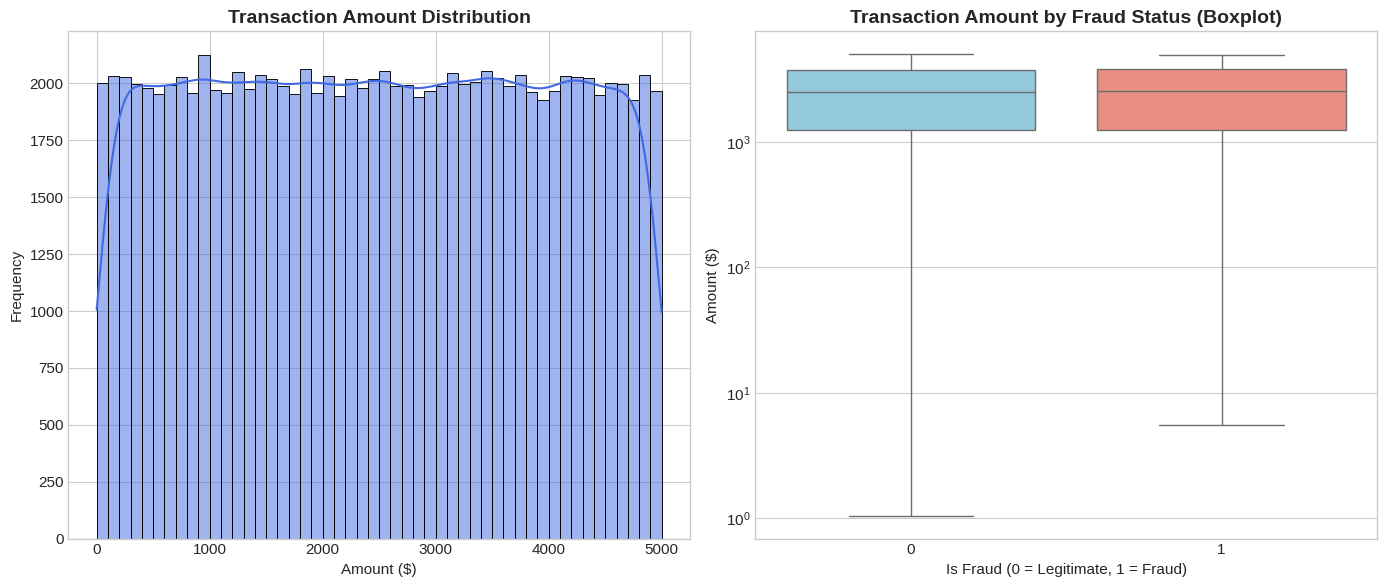

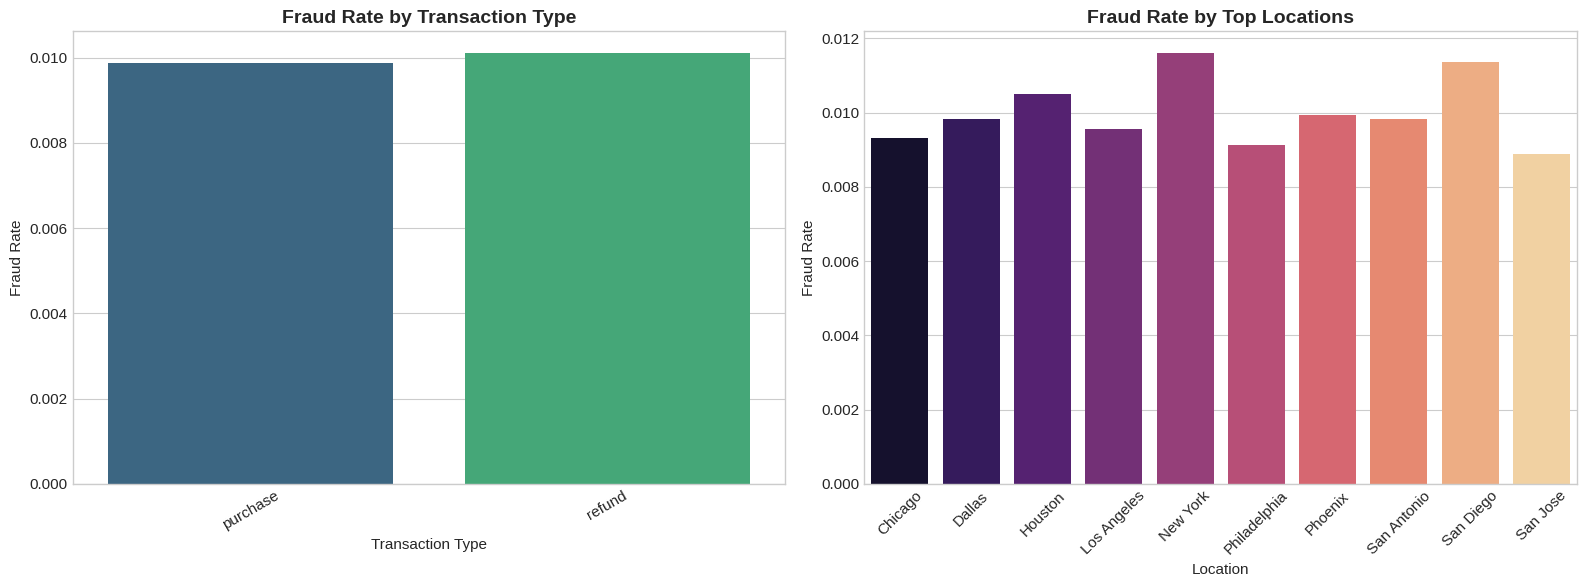

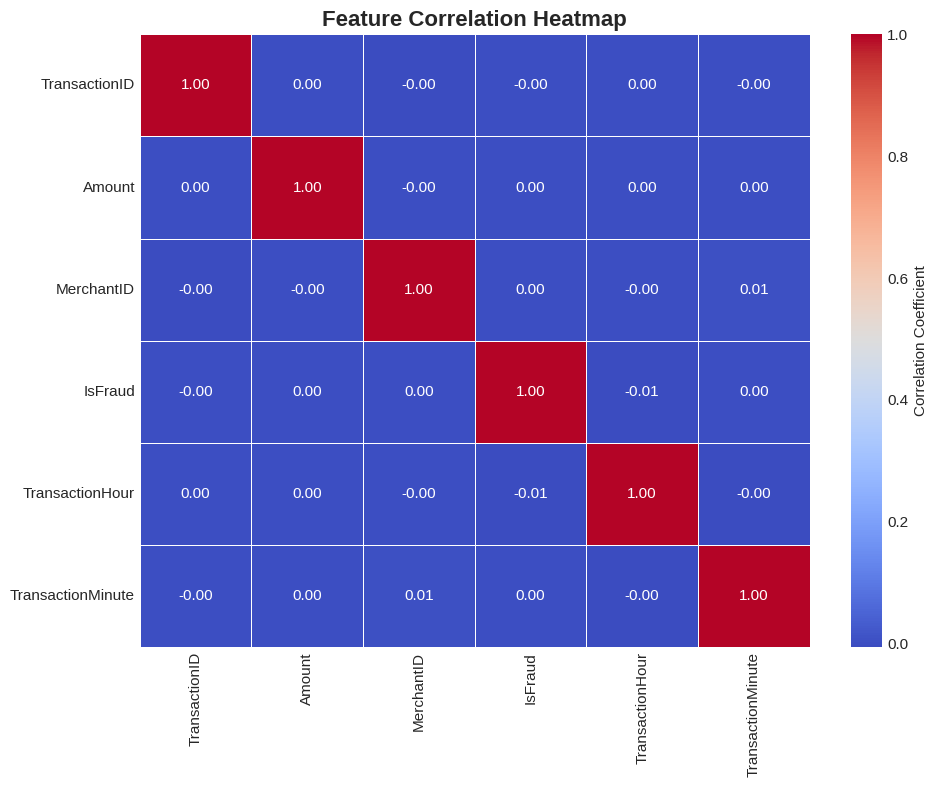

EDA and Visualizations completed successfully.


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

def parse_time_features(data):

    d = data.copy()

    try:
    
        temp_dt = pd.to_datetime(d['TransactionDate'], errors='coerce')
        d['TransactionHour'] = temp_dt.dt.hour
        d['TransactionMinute'] = temp_dt.dt.minute
    except Exception:
    
        d['TransactionHour'] = d['TransactionDate'].astype(str).str.split(':').str[0].astype(float)
    return d

df_eda = parse_time_features(df)

# Transaction Amount Distribution

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.histplot(df_eda['Amount'], bins=50, kde=True, color='royalblue')
plt.title('Transaction Amount Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Amount ($)')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
sns.boxplot(x='IsFraud', y='Amount', data=df_eda, palette=['skyblue', 'salmon'])
plt.title('Transaction Amount by Fraud Status (Boxplot)', fontsize=14, fontweight='bold')
plt.xlabel('Is Fraud (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Amount ($)')
plt.yscale('log') # Log scale due to extreme skewness in financial transactions

plt.tight_layout()
plt.show()

# 3. Fraud Rate by Transaction Type & Location

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Fraud Rate by Transaction Type
fraud_by_type = df_eda.groupby('TransactionType')['IsFraud'].mean().reset_index()
sns.barplot(x='TransactionType', y='IsFraud', data=fraud_by_type, ax=axes[0], palette='viridis')
axes[0].set_title('Fraud Rate by Transaction Type', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Transaction Type')
axes[0].set_ylabel('Fraud Rate')
axes[0].tick_params(axis='x', rotation=30)

# Fraud Rate by Location (Top 10 locations if many)
top_locations = df_eda['Location'].value_counts().head(10).index
fraud_by_loc = df_eda[df_eda['Location'].isin(top_locations)].groupby('Location')['IsFraud'].mean().reset_index()
sns.barplot(x='Location', y='IsFraud', data=fraud_by_loc, ax=axes[1], palette='magma')
axes[1].set_title('Fraud Rate by Top Locations', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Location')
axes[1].set_ylabel('Fraud Rate')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Correlation Heatmap

plt.figure(figsize=(10, 8))
numeric_cols = df_eda.select_dtypes(include=[np.number]).columns
corr_matrix = df_eda[numeric_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, cbar_kws={'label': 'Correlation Coefficient'})
plt.title('Feature Correlation Heatmap', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("EDA and Visualizations completed successfully.")

# 3. Data Cleaning, Preprocessing & Advanced Feature Engineering

Raw transaction columns describe individual events, but fraud detection relies heavily on behavioral context—specifically how a given transaction deviates from established norms for a merchant, location, or transaction type. In this section, we clean the dataset, encode categorical variables, and engineer robust behavioral features.

In [4]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder

df_clean = df.copy()

df_clean['TransactionDate'] = pd.to_datetime(df_clean['TransactionDate'], errors='coerce')
df_clean['Hour'] = df_clean['TransactionDate'].dt.hour
df_clean['Minute'] = df_clean['TransactionDate'].dt.minute

merchant_stats = df_clean.groupby('MerchantID')['Amount'].agg(['mean', 'std', 'count']).reset_index()
merchant_stats.columns = ['MerchantID', 'Merchant_Mean_Amount', 'Merchant_Std_Amount', 'Merchant_Tx_Count']
df_clean = df_clean.merge(merchant_stats, on='MerchantID', how='left')

df_clean['Amount_Deviation_Merchant'] = (df_clean['Amount'] - df_clean['Merchant_Mean_Amount']) / (df_clean['Merchant_Std_Amount'] + 1e-5)

location_stats = df_clean.groupby('Location')['Amount'].agg(['mean', 'count']).reset_index()
location_stats.columns = ['Location', 'Location_Mean_Amount', 'Location_Tx_Count']
df_clean = df_clean.merge(location_stats, on='Location', how='left')

categorical_cols = ['TransactionType', 'Location']
for col in categorical_cols:
    le = LabelEncoder()
    df_clean[col + '_Encoded'] = le.fit_transform(df_clean[col].astype(str))

cols_to_drop = ['TransactionID', 'TransactionDate', 'TransactionType', 'Location']
df_model = df_clean.drop(columns=[c for c in cols_to_drop if c in df_clean.columns])

X = df_model.drop(columns=['IsFraud'])
y = df_model['IsFraud']

scaler = StandardScaler()
numeric_cols = X.select_dtypes(include=[np.number]).columns
X[numeric_cols] = scaler.fit_transform(X[numeric_cols])

print(f"Feature matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")

Feature matrix shape: (100000, 12)
Target vector shape: (100000,)


# 4. Handling Class Imbalance & Train-Test Splitting

In fraud detection datasets, severe class imbalance is standard. Training models directly on heavily skewed data often leads to models that trivially predict the majority class. Here, we perform a stratified train-test split to preserve class proportions and apply SMOTE (Synthetic Minority Over-sampling Technique) exclusively to the training split to avoid data leakage.

In [5]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Class distribution in training set before SMOTE:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("\nClass distribution in training set after SMOTE:")
print(pd.Series(y_train_resampled).value_counts())
print(pd.Series(y_train_resampled).value_counts(normalize=True) * 100)

print(f"\nFinal Resampled Training Set Shape: {X_train_resampled.shape}")
print(f"Held-out Test Set Shape: {X_test.shape}")

Class distribution in training set before SMOTE:
IsFraud
0    79200
1      800
Name: count, dtype: int64
IsFraud
0    99.0
1     1.0
Name: proportion, dtype: float64

Class distribution in training set after SMOTE:
IsFraud
0    79200
1    79200
Name: count, dtype: int64
IsFraud
0    50.0
1    50.0
Name: proportion, dtype: float64

Final Resampled Training Set Shape: (158400, 12)
Held-out Test Set Shape: (20000, 12)


# 5. Baseline & Supervised Fraud Classification Models

In this section, establish a performance baseline using Logistic Regression and scale up to robust non-linear classifiers (Random Forest and XGBoost). We train these models on our resampled data and evaluate their performance on the held-out test set using metrics tailored for imbalanced classification.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score

models = {
    "Logistic Regression (Baseline)": LogisticRegression(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "XGBoost Classifier": XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss', n_jobs=-1)
}

model_results = {}

for name, model in models.items():
    print(f"Training and Evaluating: {name}")
    model.fit(X_train_resampled, y_train_resampled)
    
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    
    model_results[name] = {
        "model": model,
        "y_pred": y_pred,
        "y_prob": y_prob,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc
    }
    
    print(f"ROC-AUC: {roc_auc:.4f} | PR-AUC: {pr_auc:.4f}")
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    print("-" * 60 + "\n")

Training and Evaluating: Logistic Regression (Baseline)
ROC-AUC: 0.4697 | PR-AUC: 0.0090

Confusion Matrix:
[[10288  9512]
 [  110    90]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.52      0.68     19800
           1       0.01      0.45      0.02       200

    accuracy                           0.52     20000
   macro avg       0.50      0.48      0.35     20000
weighted avg       0.98      0.52      0.67     20000

------------------------------------------------------------

Training and Evaluating: Random Forest
ROC-AUC: 0.5320 | PR-AUC: 0.0116

Confusion Matrix:
[[19756    44]
 [  198     2]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     19800
           1       0.04      0.01      0.02       200

    accuracy                           0.99     20000
   macro avg       0.52      0.50      0.51     20000
weighted avg       0.98      0

# 6.Anomaly Detection, Threshold Tuning & Error Analysis

introduced an unsupervised anomaly detector (Isolation Forest) to catch abnormal patterns that supervised labels might have missed. Then perform rigorous probability threshold tuning to optimize the decision boundary instead of relying on the default 0.5 threshold, followed by an error analysis of false positives and false negatives.

In [7]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_recall_curve

iso_forest = IsolationForest(contamination=0.05, random_state=42, n_jobs=-1)
iso_forest.fit(X_train_resampled)

anomaly_scores = -iso_forest.score_samples(X_test)
print(f"Isolation Forest Anomaly Scores Range: [{anomaly_scores.min():.4f}, {anomaly_scores.max():.4f}]")

best_model_name = "XGBoost Classifier"
y_prob_best = model_results[best_model_name]["y_prob"]

precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_best)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-5)
best_threshold_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_threshold_idx]

print(f"Optimal Decision Threshold (F1-optimized): {best_threshold:.4f}")

y_pred_tuned = (y_prob_best >= best_threshold).astype(int)
print("\nClassification Report with Tuned Threshold:")
print(classification_report(y_test, y_pred_tuned))

error_df = X_test.copy()
error_df['Actual'] = y_test.values
error_df['Predicted'] = y_pred_tuned
error_df['Probability'] = y_prob_best

false_positives = error_df[(error_df['Actual'] == 0) & (error_df['Predicted'] == 1)]
false_negatives = error_df[(error_df['Actual'] == 1) & (error_df['Predicted'] == 0)]

print(f"False Positives (Wasted Review Effort): {len(false_positives)}")
print(f"False Negatives (Missed Fraud): {len(false_negatives)}")

Isolation Forest Anomaly Scores Range: [0.4262, 0.6447]
Optimal Decision Threshold (F1-optimized): 0.0283

Classification Report with Tuned Threshold:
              precision    recall  f1-score   support

           0       0.99      0.59      0.74     19800
           1       0.01      0.49      0.02       200

    accuracy                           0.59     20000
   macro avg       0.50      0.54      0.38     20000
weighted avg       0.98      0.59      0.73     20000

False Positives (Wasted Review Effort): 8172
False Negatives (Missed Fraud): 102
